# Glass Identification


In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree

from IPython.display import Image

In [20]:
glass=pd.read_csv("D:\Machine Learning\Datasets\Cases\Glass_Identification\Glass.csv")


100%|██████████| 6/6 [00:00<00:00, 11.74it/s]


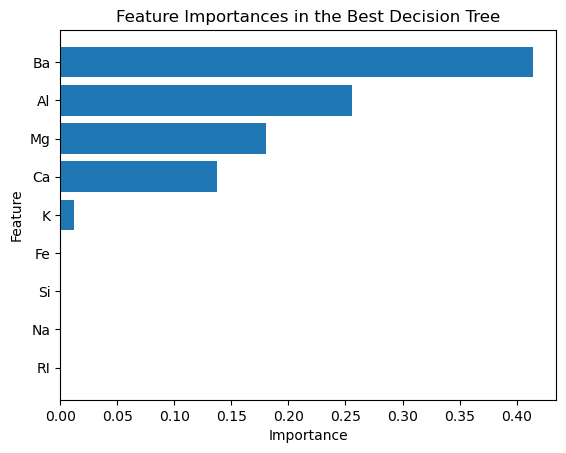

In [30]:
from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import make_column_selector
from tqdm import tqdm
X, y = glass.drop("Type", axis=1), glass["Type"]
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=25)


depths = [None, 3, 4, 5, 6, 7]
min_samples = [0.01, 2, 10, 50, 100, 250]
min_leafs = [1, 10, 50, 100, 250]
scores = []
for depth in tqdm(depths):
    for min_sample in min_samples:
        for min_leaf in min_leafs:
            dtc = DecisionTreeClassifier(max_depth=depth, 
                                         min_samples_split=min_sample, 
                                         min_samples_leaf=min_leaf, 
                                         random_state=25)
            dtc.fit(X_train, y_train)
            y_pred = dtc.predict(X_test)
            score = accuracy_score(y_test, y_pred)
            scores.append([depth, min_sample, min_leaf, score])
df_scores = pd.DataFrame(scores, columns=["max_depth", "min_samples_split", "min_samples_leaf", "score"])
df_scores.sort_values("score", ascending=False)

best_tree = DecisionTreeClassifier(random_state=25, max_depth=3, min_samples_split=2, min_samples_leaf=10)
best_tree.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": best_tree.feature_importances_})
df_imp = df_imp.sort_values("importance")
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances in the Best Decision Tree")
plt.show()
